In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/clean/ae_clean.csv", parse_dates=["month"])
df.shape

(2386, 27)

In [2]:
national = df.groupby("month")[["total_attendances", "over_4hrs", "waits_12hrs"]].sum()
national["pct_within_4hrs"] = ((1 - national["over_4hrs"] / national["total_attendances"]) * 100).round(1)
national

,total_attendances,over_4hrs,waits_12hrs,pct_within_4hrs
month,,,,
2025-04-01,2297421,579322,44648,74.8
2025-05-01,2397529,589735,42891,75.4
2025-06-01,2351581,574809,38683,75.6
2025-07-01,2408866,568304,35467,76.4
2025-08-01,2266937,546871,35909,75.9
2025-09-01,2310222,576391,44765,75.1
2025-10-01,2401266,619874,54326,74.2
2025-11-01,2347046,605140,50648,74.2
2025-12-01,2326139,608475,50789,73.8


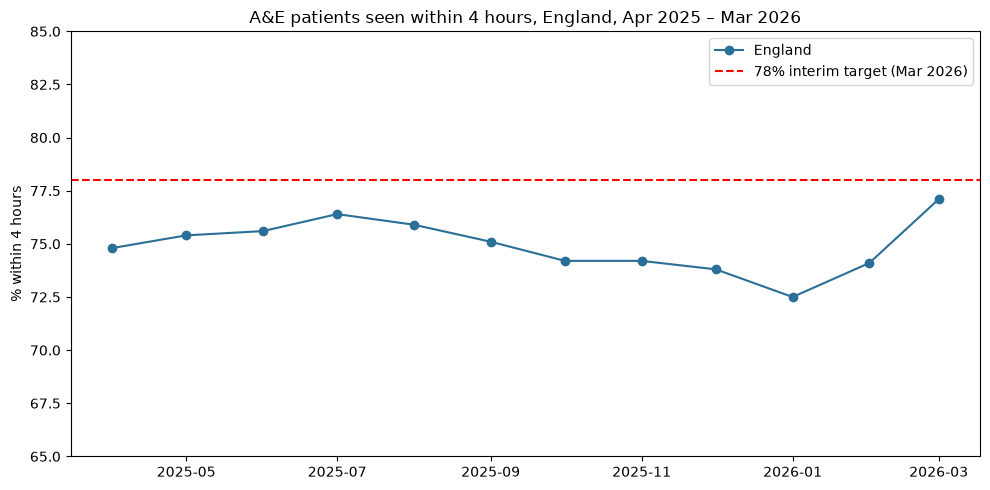

In [3]:
plt.figure(figsize=(10, 5))
plt.plot(national.index, national["pct_within_4hrs"], marker="o", color="#2a6f97", label="England")
plt.axhline(78, color="red", linestyle="--", label="78% interim target (Mar 2026)")
plt.title("A&E patients seen within 4 hours, England, Apr 2025 – Mar 2026")
plt.ylabel("% within 4 hours")
plt.ylim(65, 85)
plt.legend()
plt.tight_layout()
plt.savefig("national_trend.png", dpi=150)
plt.show()

In [4]:
national["waits_12hrs"]

month
2025-04-01    44648
2025-05-01    42891
2025-06-01    38683
2025-07-01    35467
2025-08-01    35909
2025-09-01    44765
2025-10-01    54326
2025-11-01    50648
2025-12-01    50789
2026-01-01    71517
2026-02-01    54649
2026-03-01    46665
Name: waits_12hrs, dtype: int64

In [5]:
regions = df.groupby("Parent Org")[["total_attendances", "over_4hrs", "waits_12hrs"]].sum()
regions["pct_within_4hrs"] = ((1 - regions["over_4hrs"] / regions["total_attendances"]) * 100).round(1)
regions.sort_values("pct_within_4hrs")

,total_attendances,over_4hrs,waits_12hrs,pct_within_4hrs
Parent Org,,,,
NHS ENGLAND NORTH WEST,3931831,1086444,119269,72.4
NHS ENGLAND SOUTH WEST,2467399,672117,40474,72.8
NHS ENGLAND MIDLANDS,5173253,1395166,146681,73.0
NHS ENGLAND EAST OF ENGLAND,2813784,707346,45187,74.9
NHS ENGLAND NORTH EAST AND YORKSHIRE,4399136,1055099,43059,76.0
NHS ENGLAND SOUTH EAST,4287485,981551,71931,77.1
NHS ENGLAND LONDON,4903137,1116213,104356,77.2


In [6]:
hospitals = df[df["has_major_ae"]]
trusts = hospitals.groupby("Org Code").agg(
    trust=("Org name", "last"),
    attendances=("total_attendances", "sum"),
    over_4hrs=("over_4hrs", "sum"),
    waits_12hrs=("waits_12hrs", "sum"))
trusts["pct_within_4hrs"] = ((1 - trusts["over_4hrs"] / trusts["attendances"]) * 100).round(1)
trusts = trusts.sort_values("pct_within_4hrs")

print("Trusts compared:", len(trusts))
print("Trusts at or above 78% for the year:", (trusts["pct_within_4hrs"] >= 78).sum())
trusts.head(5)

Trusts compared: 121
Trusts at or above 78% for the year: 22


,trust,attendances,over_4hrs,waits_12hrs,pct_within_4hrs
Org Code,,,,,
RJN,EAST CHESHIRE NHS TRUST,54710,28236,4105,48.4
RXW,THE SHREWSBURY AND TELFORD HOSPITAL NHS TRUST,160372,76983,16915,52.0
RD1,ROYAL UNITED HOSPITALS BATH NHS FOUNDATION TRUST,107136,44929,1509,58.1
RWA,HULL UNIVERSITY TEACHING HOSPITALS NHS TRUST,169370,69778,6183,58.8
RX1,NOTTINGHAM UNIVERSITY HOSPITALS NHS TRUST,234919,95478,8451,59.4


In [7]:
trusts.tail(5)

,trust,attendances,over_4hrs,waits_12hrs,pct_within_4hrs
Org Code,,,,,
RVW,NORTH TEES AND HARTLEPOOL NHS FOUNDATION TRUST,193838,31938,272,83.5
RWG,WEST HERTFORDSHIRE TEACHING HOSPITALS NHS TRUST,199740,30819,296,84.6
RBS,ALDER HEY CHILDREN'S NHS FOUNDATION TRUST,70785,10471,0,85.2
RTF,NORTHUMBRIA HEALTHCARE NHS FOUNDATION TRUST,282221,30257,0,89.3
RCU,SHEFFIELD CHILDREN'S NHS FOUNDATION TRUST,61282,4322,0,92.9


## Key findings

1. **England missed the 78% interim target in every month of 2025/26.** Performance ranged from 72.5% (January 2026) to 77.1% (March 2026), against the 95% constitutional standard.
2. **Winter pressure is clear:** 12-hour waits from decision to admit peaked at 71,517 in January 2026, roughly double the summer level (~35,000).
3. **Regional gap of almost 5 points:** North West was lowest (72.4%), London highest (77.2%).
4. **Only 22 of 121 trusts with a major A&E reached 78% across the year.** The lowest was East Cheshire (48.4%). The highest were children's hospitals, which aren't directly comparable with general A&Es.
5. **The 4-hour score and 12-hour waits tell different stories.** London had the best 4-hour performance (77.2%) but the third-highest 12-hour waits (104,356), suggesting bed availability is a separate problem from front-door speed.

## Method notes
- Percentages are calculated from summed attendances, not averaged across organisations, so larger departments carry proportionate weight.
- Trust rankings include only organisations with a Type 1 (major) A&E, grouped by organisation code to handle name changes.
- Totals were reconciled against NHS England's published TOTAL rows.